# K_Mean_Model

In [1]:
# import libraries

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

In [2]:
# load the dataset 

df = pd.read_csv("C:\\Users\\Shree\\Documents\\MACHINE_LEARNING\\K_Mean_Model\\Mall_Customers.csv")

In [3]:
df

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
...,...,...,...,...,...
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18


In [6]:
df.isnull().sum()

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [7]:
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


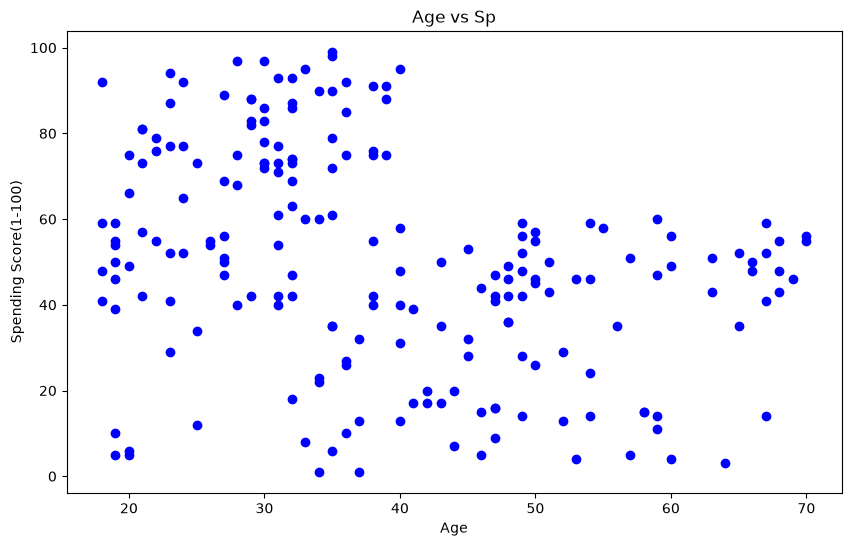

In [11]:
plt.figure(figsize=(10,6))
plt.scatter(df["Age"],df["Spending Score (1-100)"],color = "blue")
plt.xlabel("Age")
plt.ylabel("Spending Score(1-100)")
plt.title("Age vs Sp")
plt.show()



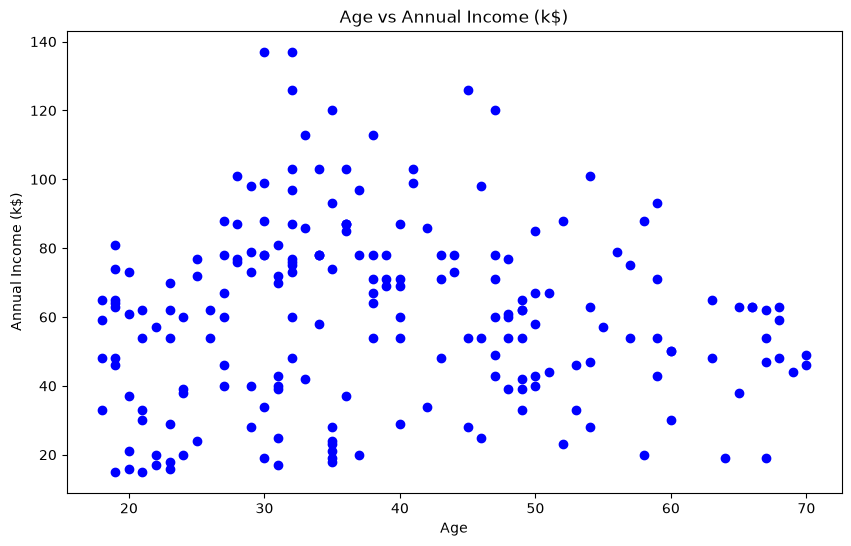

In [15]:
plt.figure(figsize=(10,6))
plt.scatter(df["Age"],df["Annual Income (k$)"],color = "blue")
plt.xlabel("Age")
plt.ylabel("Annual Income (k$)")
plt.title("Age vs Annual Income (k$)")
plt.show()

In [12]:
df.drop(["CustomerID","Gender"],axis = 1, inplace = True)

In [ ]:
# feature scaling

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

scaled_data = scaler.fit_transform(df)




In [40]:
from sklearn.cluster import KMeans

# Create an instance of the model
kmeans = KMeans(n_clusters=6, random_state=42)

# Fit the model to the scaled data
kmeans.fit(scaled_data)

# Get the cluster labels
labels = kmeans.labels_

# Print the cluster labels
print(labels)

[2 2 5 2 5 2 5 2 5 2 5 2 5 2 5 2 5 2 5 2 5 2 5 2 5 2 5 2 5 2 5 2 5 2 5 2 5
 2 5 2 0 2 5 2 5 2 0 3 3 3 0 2 3 0 0 0 0 0 3 0 0 3 0 0 0 3 0 0 3 3 0 0 0 0
 0 3 0 3 3 0 0 3 0 0 3 0 0 3 3 0 0 3 0 3 3 3 0 3 0 3 3 0 0 3 0 3 0 0 0 0 0
 3 3 3 3 3 0 0 0 0 3 3 3 1 3 1 4 1 4 1 4 1 3 1 3 1 4 1 3 1 4 1 3 1 3 1 4 1
 4 1 4 1 4 1 4 1 4 1 4 1 0 1 3 1 4 1 4 1 4 1 4 1 4 1 4 1 4 1 4 1 4 1 4 1 4
 1 4 1 4 1 4 1 4 1 4 1 4 1 4 1]


In [41]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Create the model
kmeans = KMeans(n_clusters=7, random_state=42)

# Fit the model
kmeans.fit(scaled_data)

# Get cluster labels
labels = kmeans.labels_

# Calculate silhouette score
silhouette_avg = silhouette_score(scaled_data, labels)

# Print the score
print("Silhouette Score for 2 clusters:", silhouette_avg)

Silhouette Score for 2 clusters: 0.410091114520974


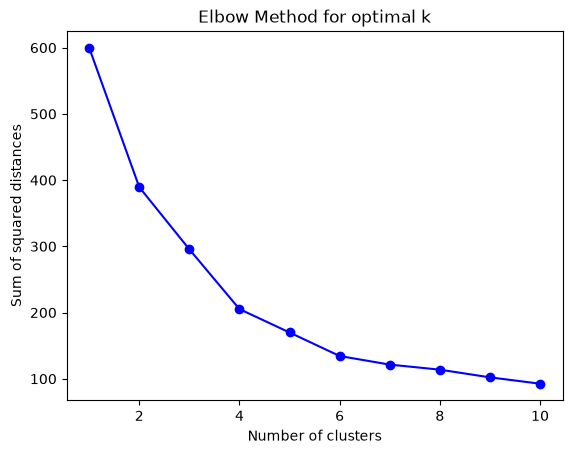

In [42]:
# calculate the sum of squared distances for different number of clusters

ssd = []
K_range = range(1,11)
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(scaled_data)
    ssd.append(kmeans.inertia_)

# plot the elbow curve

plt.plot(K_range, ssd, "bo-")
plt.xlabel("Number of clusters")
plt.ylabel("Sum of squared distances")
plt.title("Elbow Method for optimal k")
plt.show()

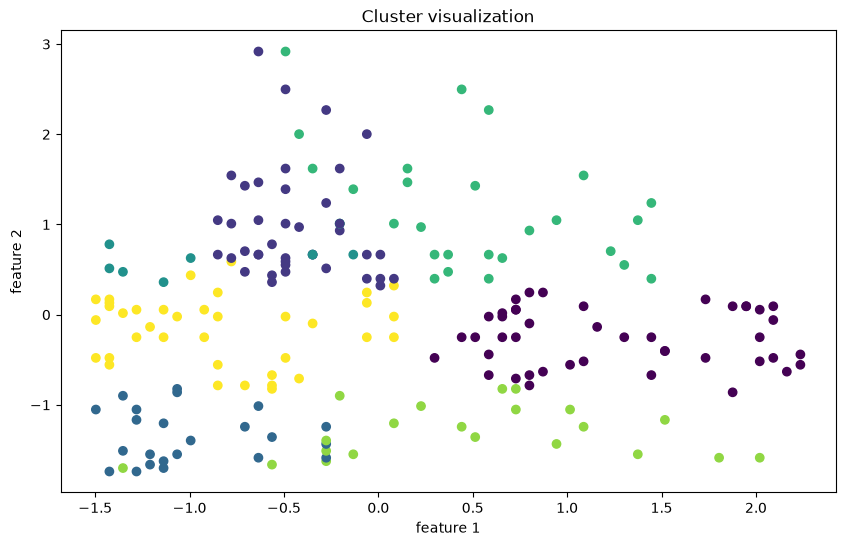

In [44]:
# visulize the clusters

# using label visualization

plt.figure(figsize=(10,6))
plt.scatter(scaled_data[:,0], scaled_data[:,1], c=labels, cmap="viridis")
plt.xlabel("feature 1")
plt.ylabel("feature 2")
plt.title("Cluster visualization")
plt.show()